# 🔩 링크 가중치 예측 예제 — 트러스 부재의 강성 찾기

**건설빅데이터분석 · 그래프 신경망 · W09 링크 예측 → 링크 가중치 · 예제 노트북 2 (실행 결과 포함)**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/baekja/Lecture_GNN-AE-Practice/blob/main/PyG_LinkPred_Truss/truss_linkweight_example.ipynb)

> 예제 노트북 1([누락 부재 찾기](https://colab.research.google.com/github/baekja/Lecture_GNN-AE-Practice/blob/main/PyG_LinkPred_Truss/truss_linkpred_example.ipynb))에서는 부재가 **있는가**(0/1)를 맞혔습니다.
> 구조해석에서 부재는 있다/없다로 끝나지 않습니다. 부재마다 **강성** $EA/L$ 이 있고, 손상되면 강성이 떨어집니다.
> 링크 예측을 일반화한 **링크 가중치 예측(엣지 회귀)** 으로 넘어가면 "부재가 얼마나 센가"를 맞히게 되고,
> **강성 0 = 부재 없음**으로 두면 두 문제가 하나로 합쳐집니다.

| 절 | 내용 |
|:-:|---|
| 1 | 1단계 요약 — 부재 존재 예측(예제 노트북 1)과 이번 질문 |
| 2 | 데이터 — 1단계와 같은 트러스 60동에 손상 · 하중 · 계측 변위 |
| 3 | 식별 가능성 — 힘을 받지 않는 부재의 강성은 아무도 모른다 |
| 4 | 고전 역해석 — 평형식 최소제곱 · 트러스별 역해석 |
| 5 | GNN 지도학습형 — 인코더는 그대로, 디코더(엣지 회귀)와 손실(MSE)만 바꾼다 |
| 6 | 물리결합형 · 혼합 — 미분 가능한 직접강성법을 손실 안에 |
| 7 | 직접강성법 검증 — 처음 보는 하중에서도 맞는가 |
| 8 | 측정점이 적으면 — 해가 하나로 정해지지 않는다 |
| 9 | 3단계 — 존재와 강성을 한 번에 (강성 0 = 부재 없음) |
| 10 | 시드 3개로 다시 · 한 표로 비교 |

**사용법** — Colab에서 **파일 → Drive에 사본 저장** 후 위에서부터 차례대로 실행(`Shift + Enter`). GPU는 필요 없습니다(CPU 런타임 그대로).

## 0. 준비 — PyG 설치와 라이브러리

In [1]:
import importlib.util, subprocess
if importlib.util.find_spec("torch_geometric") is None:           # Colab 처음 실행이면 PyG 설치
    subprocess.run(["pip", "install", "-q", "torch_geometric"], check=True)

import time, math, warnings
warnings.filterwarnings("ignore")                                   # 선택 확장 모듈 안내 등 경고 숨김
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch_geometric as pyg
from torch import nn
from torch_geometric.nn import GCN
from sklearn.metrics import roc_auc_score
from scipy.optimize import nnls
torch.set_num_threads(1)                                            # 작은 그래프라 스레드 1개가 더 빠르고, 같은 시드면 같은 결과가 나온다
print("torch", torch.__version__, "| PyG", pyg.__version__)
T0 = time.time()                                                    # ⏱ 노트북 전체 시간

torch 2.14.1 | PyG 2.8.1


## 1. 1단계 요약 — 부재 존재 예측
- 예제 노트북 1: 시험 트러스 20동에서 부재 20%를 가리고 "어느 절점 쌍이 부재인가"를 맞혔다. 입력은 **형상(좌표 · 보이는 부재)뿐**
- 결과(예제 노트북 1의 출력, 시드 3개 평균). 무작위 음성 AUC는 학습한 모델 모두 0.9를 넘었다. 그러나 가까운 후보 중에서 골라 트러스를 완성하는 **완전 복원**은 최고 0.467이었고, 대칭인 두 대각선 중 진짜를 고르는 **대각재 방향 승률**은 최고 0.805였다.

| 1단계 방법 | 무작위 음성 AUC | 대각재 방향 승률 | 완전 복원 비율 |
|---|:-:|:-:|:-:|
| 거리(휴리스틱) | 0.986 | 0.500 | 0.267 |
| GAE | 0.922 | 0.761 | 0.000 |
| VGAE | 0.918 | 0.805 | 0.033 |
| GNN + MLP 디코더 | 0.992 | 0.802 | 0.467 |
| SEAL 간이판 | 0.953 | 0.769 | 0.217 |

*완전 복원은 실행 환경에 따라 조금 달라진다(예: 실제 Colab에서 거리 0.250).*

**이번 질문**
1. 부재가 모두 보이면 각 부재가 **얼마나 센지**(강성) 맞힐 수 있는가?
2. **거동 정보**(하중 · 변위)를 주면 1단계의 대칭 문제가 풀리는가?

**존재 → 가중치**: 링크 예측의 정답 $y_{ij}\in\{0,1\}$ 을 실수 가중치 $w_{ij} = s_{ij}\,EA_0/L_{ij} \ge 0$ 으로 바꾼다. 맞힐 값은 **강성비** $s = EA/EA_0$ 이다(무차원, 손상 $= 1 - s$). $EA/L$ 대신 $s$ 를 쓰는 이유는 길이 $L$ 은 좌표로 이미 알기 때문이다 — 모르는 것만 맞힌다. 손실도 BCE에서 **MSE**로 바뀐다.

## 2. 데이터 — 같은 트러스 60동에 손상 · 하중 · 계측
- 트러스: 예제 노트북 1과 **똑같은** 60동(같은 생성 코드 · 같은 시드). 시험 트러스 7번도 그대로다
- **손상**: 트러스마다 부재 1–3개의 강성을 원래의 30–80%로 낮춘다. 나머지는 $s = 1$. $EA_0$ = 200 GPa × 2000 mm² = 400 MN
- **식별용 하중 3개**: 모든 절점에 무작위 수평(±5 kN) · 수직(−20 ~ +5 kN) 하중을 준다. 이유는 3절에서 본다
- **계측 변위**: 참 강성으로 직접강성법을 풀어 얻은 절점 변위(잡음 없음). 실제로는 변위계 · 영상 계측 등으로 잰다
- **검증 하중**: 1단계와 같은 표준 하중(아래현 내부 절점마다 10 kN 하향). 학습 · 역해석에 쓰지 않는 **새 하중**이다(7절)

In [2]:
EA0, NC = 200e9 * 2e-3, 3                                           # 원래 축강성 EA0 (N), 식별용 하중 수

def make_truss(kind, n, w, h):
    """평행현 트러스(예제 노트북 1과 같은 코드). 반환: 절점 좌표(m), 부재 목록, 대각재 목록, 같은 패널의 '반대 대각선' 목록"""
    pos = np.array([(i * w, 0.0) for i in range(n + 1)] + [(i * w, h) for i in range(n + 1)])
    b, t = (lambda i: i), (lambda i: n + 1 + i)
    members = ([(b(i), b(i + 1)) for i in range(n)] + [(t(i), t(i + 1)) for i in range(n)]
               + [(b(i), t(i)) for i in range(n + 1)])
    diag, other = [], []
    for i in range(n):
        left = (i + 0.5) < n / 2
        down = (t(i), b(i + 1)) if left else (b(i), t(i + 1))
        up = (b(i), t(i + 1)) if left else (t(i), b(i + 1))
        d, o = (down, up) if kind == "Pratt" else (up, down)
        diag.append(d); other.append(o)
    return pos, members + diag, diag, other

def make_set(count, first_kind, rng):
    out = []
    for g in range(count):
        kind = ["Pratt", "Howe"][(g + first_kind) % 2]
        n = int(rng.integers(4, 9)); w = float(rng.uniform(1.5, 3.0)); h = float(rng.uniform(1.5, 3.0))
        pos, mem, diag, other = make_truss(kind, n, w, h)
        out.append(dict(kind=kind, n=n, w=w, h=h, pos=pos, mem=mem, diag=diag, other=other))
    return out

def free_dofs(N, n): return [i for i in range(2 * N) if i not in (0, 1, 2 * n + 1)]   # 왼쪽 아래 핀(x, y) · 오른쪽 아래 롤러(y) 고정

def dsm(pos, pairs, s, F, n):
    """직접강성법: 부재 강성 s·EA0/L 을 조립해 K u = F 를 푼다. F: (2N, 하중 수) → 변위 (2N, 하중 수)"""
    N = len(pos); K = np.zeros((2 * N, 2 * N))
    for k, (u, v) in enumerate(pairs):
        d = pos[v] - pos[u]; L = np.hypot(*d); c, sn = d / L
        T = np.array([-c, -sn, c, sn]); idx = [2 * u, 2 * u + 1, 2 * v, 2 * v + 1]
        K[np.ix_(idx, idx)] += s[k] * EA0 / L * np.outer(T, T)
    fr = free_dofs(N, n); U = np.zeros((2 * N, F.shape[1]))
    U[fr] = np.linalg.solve(K[np.ix_(fr, fr)], F[fr])
    return U

def std_load(tr, P=10e3):                                           # 1단계 표준 하중: 아래현 내부 절점마다 P 하향
    F = np.zeros((2 * len(tr["pos"]), 1)); F[[2 * i + 1 for i in range(1, tr["n"])], 0] = -P; return F

def max_defl(tr, pairs, s):                                         # 표준 하중에서 최대 처짐 (mm)
    return -dsm(tr["pos"], pairs, s, std_load(tr), tr["n"])[1::2].min() * 1e3

def add_behavior(tset, rng):
    """손상(부재 1–3개, s = 0.3–0.8) · 식별용 하중 3개 · 계측 변위"""
    for tr in tset:
        pos, n, m = tr["pos"], tr["n"], len(tr["mem"]); N = len(pos)
        s = np.ones(m); kd = int(rng.integers(1, 4)); dmg = rng.choice(m, kd, replace=False)
        s[dmg] = rng.uniform(0.3, 0.8, kd)
        F = np.zeros((2 * N, NC)); F[0::2] = rng.uniform(-5e3, 5e3, (N, NC)); F[1::2] = rng.uniform(-20e3, 5e3, (N, NC))
        F[[0, 1, 2 * n + 1]] = 0                                     # 지점 자유도의 하중은 반력이 받는다 → 0
        tr.update(s=s, dmg=sorted(dmg.tolist()), F=F, U=dsm(pos, tr["mem"], s, F, n))
    return tset

def make_data(seed):
    r = np.random.default_rng(seed)                                  # 예제 노트북 1과 같은 시드 · 같은 순서 → 같은 트러스
    train_set, test_set = make_set(40, 0, r), make_set(20, 1, r)
    hid_order = r.permutation(sum(len(t["mem"]) for t in test_set))  # 1단계 3절 hide()와 같은 난수 → 같은 '가린 부재'(9절)
    rd = np.random.default_rng(1000 + seed)                          # 손상 · 하중은 다른 난수열(트러스 모양은 1단계와 같게)
    add_behavior(train_set, rd); add_behavior(test_set, rd)
    return train_set, test_set, hid_order

train_set, test_set, hid_order = make_data(0)
U_all = np.concatenate([t["U"][free_dofs(len(t["pos"]), t["n"])].ravel() for t in train_set])
print(f"학습 {len(train_set)}동(부재 {sum(len(t['mem']) for t in train_set)}, 손상 {sum(len(t['dmg']) for t in train_set)})"
      f" · 시험 {len(test_set)}동(부재 {sum(len(t['mem']) for t in test_set)}, 손상 {sum(len(t['dmg']) for t in test_set)})")
print(f"계측 변위: 표준편차 {U_all.std() * 1e3:.2f} mm · 최대 {np.abs(U_all).max() * 1e3:.1f} mm (학습 트러스)")
t7 = test_set[7]
print(f"시험 트러스 7: {t7['kind']} {t7['n']}패널 · 부재 {len(t7['mem'])} · 손상 부재 {t7['dmg']} → s = {np.round(t7['s'][t7['dmg']], 2).tolist()}")

학습 40동(부재 1080, 손상 86) · 시험 20동(부재 476, 손상 43)
계측 변위: 표준편차 7.24 mm · 최대 68.3 mm (학습 트러스)
시험 트러스 7: Pratt 6패널 · 부재 25 · 손상 부재 [0, 3, 22] → s = [0.43, 0.33, 0.64]


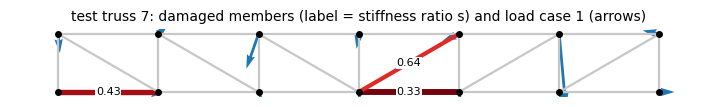

In [3]:
def draw_s(ax, tr, s, title, label_min=0.1):
    """부재를 강성비로 색칠: 회색 = 손상 없음(s ≈ 1), 붉을수록 손상(1 − s)이 크다. 숫자 = s"""
    for k, (u, v) in enumerate(tr["mem"]):
        d = float(np.clip(1 - s[k], 0, 1))
        col = "0.78" if d < 0.05 else plt.cm.Reds(0.35 + 0.65 * min(d / 0.7, 1))
        ax.plot(*zip(tr["pos"][u], tr["pos"][v]), color=col, lw=1.6 + 4 * d, solid_capstyle="round")
        if d >= label_min:
            ax.text(*(tr["pos"][u] + tr["pos"][v]) / 2, f"{s[k]:.2f}", fontsize=8, ha="center", va="center",
                    bbox=dict(fc="white", ec="none", pad=0.4))
    ax.scatter(*tr["pos"].T, s=16, color="k", zorder=3)
    ax.set_title(title, fontsize=10); ax.set_aspect("equal"); ax.axis("off")

fig, ax = plt.subplots(figsize=(9, 3.2))
draw_s(ax, t7, t7["s"], "test truss 7: damaged members (label = stiffness ratio s) and load case 1 (arrows)")
F1 = t7["F"][:, 0].reshape(-1, 2) / 20e3 * 0.8 * t7["w"]               # 하중 1을 화살표로 (20 kN = 패널 폭의 0.8배)
ax.quiver(t7["pos"][:, 0], t7["pos"][:, 1], F1[:, 0], F1[:, 1], angles="xy", scale_units="xy", scale=1,
          color="tab:blue", width=0.004)
ax.margins(0.08); plt.show()

## 3. 식별 가능성 — 힘을 받지 않는 부재의 강성은 아무도 모른다
- 손상된 부재를 찾으려면 그 부재가 **힘을 받아야** 한다. 힘이 0이면 늘지도 줄지도 않아서, 강성이 얼마이든 변위가 같다 → **어떤 방법으로도** 알 수 없다(모델의 한계가 아니라 데이터의 한계)
- 이 트러스들은 정정($m + r = 2j$, 예제 노트북 1의 2절)이라 부재력은 **강성과 무관하게** 평형만으로 정해진다 → 무응력 부재는 하중만 보고 셀 수 있다
- 흔한 재하 시험 3종(① 아래현 전 절점 10 kN ② 경간 중앙 근처 아래현 한 점 20 kN ③ 위현 왼쪽 끝 수평 10 kN)과 2절의 무작위 절점 하중 3개를 비교한다

흔한 재하 시험 3종: 무응력 부재 150 / 1556 (9.6%) · 그중 손상 부재 11개
무작위 절점 하중 3개: 무응력 부재 0 / 1556


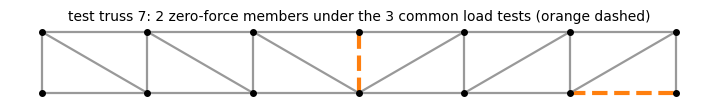

In [4]:
def member_forces(tr, F):
    """부재력(인장 +, 하중마다). 정정 트러스라 강성과 무관하므로 s = 1로 풀어도 같다"""
    U = dsm(tr["pos"], tr["mem"], np.ones(len(tr["mem"])), F, tr["n"])
    out = []
    for u, v in tr["mem"]:
        d = tr["pos"][v] - tr["pos"][u]; L = np.hypot(*d); c, sn = d / L
        du = U[[2 * v, 2 * v + 1]] - U[[2 * u, 2 * u + 1]]
        out.append(EA0 / L * (c * du[0] + sn * du[1]))
    return np.array(out)                                              # (부재 수, 하중 수)

def common_tests(tr):
    N, n = len(tr["pos"]), tr["n"]; F = np.zeros((2 * N, 3))
    F[[2 * i + 1 for i in range(1, n)], 0] = -10e3                    # ① 아래현 전 절점
    F[2 * (n // 2) + 1, 1] = -20e3                                    # ② 경간 중앙 근처 한 점
    F[2 * (n + 1), 2] = 10e3                                          # ③ 위현 왼쪽 끝 수평
    return F

def zero_force(tr, F, tol=1e-6):                                      # 모든 하중에서 힘이 0인 부재
    Nf = np.abs(member_forces(tr, F)); return np.where(Nf.max(1) < tol * Nf.max())[0]

all_tr = train_set + test_set; m_all = sum(len(t["mem"]) for t in all_tr)
z_common = [zero_force(t, common_tests(t)) for t in all_tr]
z_random = [zero_force(t, t["F"]) for t in all_tr]
print(f"흔한 재하 시험 3종: 무응력 부재 {sum(map(len, z_common))} / {m_all} ({sum(map(len, z_common)) / m_all:.1%})"
      f" · 그중 손상 부재 {sum(len(set(z) & set(t['dmg'])) for z, t in zip(z_common, all_tr))}개")
print(f"무작위 절점 하중 3개: 무응력 부재 {sum(map(len, z_random))} / {m_all}")

fig, ax = plt.subplots(figsize=(9, 3.0))
z7 = set(z_common[40 + 7].tolist())
for k, (u, v) in enumerate(t7["mem"]):
    ax.plot(*zip(t7["pos"][u], t7["pos"][v]), color="tab:orange" if k in z7 else "0.6",
            lw=3 if k in z7 else 1.6, ls="--" if k in z7 else "-")
ax.scatter(*t7["pos"].T, s=16, color="k", zorder=3); ax.set_aspect("equal"); ax.axis("off")
ax.set_title(f"test truss 7: {len(z7)} zero-force members under the 3 common load tests (orange dashed)", fontsize=10)
plt.show()

## 4. 고전 역해석 — 먼저 물리로 풀어 본다
**평형식 최소제곱.** 계측이 **모든 절점**에 있으면 절점 평형식 $\mathbf K(\mathbf s)\,\mathbf u = \mathbf f$ 가 $\mathbf s$ 에 대해 **선형**이다:

$$\sum_k s_k\,\underbrace{\frac{EA_0}{L_k}\,(\mathbf t_k\!\cdot\!\Delta\mathbf u_k)}_{s = 1\text{일 때의 부재력}}\,\mathbf b_k = \mathbf f$$

*읽는 법 —* $\mathbf t_k$ 는 부재 방향 단위벡터, $\Delta\mathbf u_k$ 는 두 끝 절점의 변위 차, $\mathbf b_k$ 는 부재력을 양 끝 절점 힘으로 나눠 주는 벡터다. 식의 수는 하중 3개 × 자유도 $2j-3$, 미지수는 부재 수 $m = 2j-3$ 이다. 식이 미지수의 3배이므로 최소제곱으로 한 번에 풀린다.

**트러스별 역해석.** 강성 $\mathbf s$ 를 변수로 두고, 직접강성법으로 푼 변위가 계측과 같아지도록 경사하강한다. 6절 물리결합형 손실과 같은 계산을 모델 없이 트러스마다 따로 하는 것이다. 이를 위해 직접강성법을 **torch로** 짠다(`BatchDSM`). 여러 트러스를 한 번에 풀고, 강성까지 기울기가 흐른다.

In [5]:
def equilibrium_ls(tr, pairs=None, nonneg=False):
    """평형식 최소제곱: 계측 변위 U와 하중 F로 강성비 s를 바로 푼다 (모든 절점 계측이 필요). nonneg = s ≥ 0 조건"""
    pairs = tr["mem"] if pairs is None else pairs
    fr = free_dofs(len(tr["pos"]), tr["n"]); A = []
    for u, v in pairs:
        d = tr["pos"][v] - tr["pos"][u]; L = np.hypot(*d); c, sn = d / L
        T = np.array([-c, -sn, c, sn]); idx = [2 * u, 2 * u + 1, 2 * v, 2 * v + 1]
        col = np.zeros((2 * len(tr["pos"]), NC)); col[idx] = EA0 / L * np.outer(T, T @ tr["U"][idx])
        A.append(col[fr].ravel(order="F"))
    A, f = np.array(A).T, tr["F"][fr].ravel(order="F")
    return nnls(A, f)[0] if nonneg else np.linalg.lstsq(A, f, rcond=None)[0]

class BatchDSM:
    """여러 트러스의 직접강성법을 torch로 한 번에(강성 s에 대해 미분 가능).
    pairs_list[b] = 트러스 b의 부재(또는 후보) 목록 · sensors = "all"(모든 자유도) 또는 "bottom"(아래현 수직 변위만)"""
    def __init__(self, tset, pairs_list, sensors="all"):
        frs = [free_dofs(len(t["pos"]), t["n"]) for t in tset]; B, D = len(tset), max(map(len, frs))
        bi, I, T, L = [], [], [], []
        self.F = torch.zeros(B, D, NC, dtype=torch.float64); self.U = torch.zeros_like(self.F)
        self.pad = torch.zeros(B, D, dtype=torch.bool); self.mask = torch.zeros(B, D, dtype=torch.bool)
        for b, (tr, pairs, fr) in enumerate(zip(tset, pairs_list, frs)):
            mp = np.full(2 * len(tr["pos"]), D); mp[fr] = np.arange(len(fr))   # 고정 자유도 → 버리는 칸 D
            for u, v in pairs:
                d = tr["pos"][v] - tr["pos"][u]; l = np.hypot(*d); c, sn = d / l
                bi.append(b); I.append(mp[[2 * u, 2 * u + 1, 2 * v, 2 * v + 1]]); T.append([-c, -sn, c, sn]); L.append(l)
            self.F[b, :len(fr)] = torch.from_numpy(tr["F"][fr]); self.U[b, :len(fr)] = torch.from_numpy(tr["U"][fr])
            self.pad[b, len(fr):] = True
            rows = range(len(fr)) if sensors == "all" else [k for k, q in enumerate(fr) if q % 2 == 1 and q // 2 <= tr["n"]]
            self.mask[b, list(rows)] = True
        self.bi, self.I = torch.tensor(bi), torch.tensor(np.array(I))
        self.T, self.L = torch.tensor(T, dtype=torch.float64), torch.tensor(L, dtype=torch.float64)
        self.B, self.D = B, D
        self.scale = (self.U.abs() * self.mask[..., None]).amax(1, keepdim=True)   # 트러스 · 하중마다 최대 계측 변위
    def solve(self, s):
        ke = (s.double() * EA0 / self.L)[:, None, None] * self.T[:, :, None] * self.T[:, None, :]
        idx = (self.bi[:, None, None].expand(-1, 4, 4), self.I[:, :, None].expand(-1, 4, 4), self.I[:, None, :].expand(-1, 4, 4))
        K = torch.zeros(self.B, self.D + 1, self.D + 1, dtype=torch.float64).index_put(idx, ke, accumulate=True)
        K = K[:, :self.D, :self.D] + torch.diag_embed(self.pad.double())   # 트러스마다 자유도 수가 달라 생긴 빈 칸은 1
        return torch.linalg.solve(K, self.F)
    def loss(self, s):                                               # 계측점 변위의 정규화 MSE
        e = ((self.solve(s) - self.U) / self.scale) ** 2 * self.mask[..., None]
        return e.sum() / (self.mask.sum() * NC)

def per_truss_inverse(dsm_b, n_pairs, s0=1.0, steps=1500):
    """트러스별 역해석: 강성비 s(0–1.2)를 변수로 두고 직접강성법 변위를 계측에 맞춘다 (모델 없음)"""
    z = torch.full((n_pairs,), math.log((s0 / 1.2) / (1 - s0 / 1.2)), dtype=torch.float64, requires_grad=True)
    opt = torch.optim.Adam([z], lr=0.05)
    for _ in range(steps):
        loss = dsm_b.loss(1.2 * torch.sigmoid(z)); opt.zero_grad(); loss.backward(); opt.step()
    return (1.2 * torch.sigmoid(z)).detach().numpy(), float(loss)

def evaluate_s(tset, s_pred):
    """강성 지표 + 직접강성법 검증. s_pred = 시험 트러스들의 부재 강성비를 이어 붙인 것"""
    s_true = np.concatenate([t["s"] for t in tset])
    dmg = np.concatenate([np.isin(np.arange(len(t["mem"])), t["dmg"]) for t in tset])
    err_u, err_d, hit, off = [], [], [], 0
    for t in tset:
        m = len(t["mem"]); sp = np.clip(s_pred[off:off + m], 1e-3, None); off += m
        err_u.append(np.linalg.norm(dsm(t["pos"], t["mem"], sp, t["F"], t["n"]) - t["U"]) / np.linalg.norm(t["U"]))
        d0, d1 = max_defl(t, t["mem"], t["s"]), max_defl(t, t["mem"], sp); err_d.append(abs(d1 - d0) / d0)
        k = len(t["dmg"]); hit.append(len(set(np.argsort(sp, kind="stable")[:k].tolist()) & set(t["dmg"])) / k)
    e = np.abs(s_pred - s_true)
    return {"강성 MAE": e.mean(), "손상 부재 MAE": e[dmg].mean(), "손상 AUC": roc_auc_score(dmg, -s_pred),
            "손상 적중": np.mean(hit), "변위 오차(계측 하중)": np.mean(err_u), "처짐 오차(새 하중)": np.mean(err_d)}

rows = {"기준선: s = 1 (손상 없음 가정)": evaluate_s(test_set, np.ones(sum(len(t["mem"]) for t in test_set)))}
t = time.time(); s_ls = np.concatenate([equilibrium_ls(tr) for tr in test_set])
rows["고전: 평형식 최소제곱"] = evaluate_s(test_set, s_ls); print(f"평형식 최소제곱 ⏱ {time.time() - t:.2f}초")
t = time.time(); dsm_te = BatchDSM(test_set, [tr["mem"] for tr in test_set])
s_inv, l_inv = per_truss_inverse(dsm_te, len(dsm_te.L))
rows["고전: 트러스별 역해석"] = evaluate_s(test_set, s_inv); print(f"트러스별 역해석(1500회) ⏱ {time.time() - t:.1f}초 · 마지막 손실 {l_inv:.1e}")
pd.DataFrame(rows).T.round(3)

평형식 최소제곱 ⏱ 0.02초


트러스별 역해석(1500회) ⏱ 1.3초 · 마지막 손실 1.3e-08


,강성 MAE,손상 부재 MAE,손상 AUC,손상 적중,변위 오차(계측 하중),처짐 오차(새 하중)
기준선: s = 1 (손상 없음 가정),0.041,0.451,0.5,0.05,0.088,0.068
고전: 평형식 최소제곱,0.000,0.000,1.0,1.00,0.000,0.000
고전: 트러스별 역해석,0.003,0.003,1.0,1.00,0.000,0.000


- **손상 적중** = 트러스마다 강성이 가장 낮게 나온 $k$ 개($k$ = 손상 부재 수)가 실제 손상 부재인 비율 · **손상 AUC** = 손상 부재와 멀쩡한 부재를 $1-s$ 로 줄 세운 대결 승률
- 기준선(모두 $s = 1$)의 강성 MAE가 이미 작은 것은 대부분의 부재가 멀쩡하기 때문이다. 그래서 **손상 AUC · 적중**으로 손상 위치를 따로 본다
- 계측이 충분하면 **물리만으로** 거의 정확히 풀린다. 이것이 GNN이 넘어야 할 상한이다. 그러면 GNN은 왜 쓰는가? → 5–6절, 8절

## 5. GNN 지도학습형 — 인코더는 그대로, 디코더와 손실만 바꾼다
예제 노트북 1의 GNN + MLP 디코더에서 **인코더(2층 GCN)는 그대로** 두고 셋을 바꾼다.
1. **입력 피처**에 거동 정보를 더한다
   - 노드 22개: 1단계 4개(좌표 $x/L$ · $y/h$ · 지점 · 보이는 부재 수/4) + 하중마다 ($F_x, F_y, u_x, u_y$) 12개 + **$s = 1$ 이라 가정한 절점 평형 잔차** 6개 ← *물리를 피처로*
   - 평형 잔차 $\mathbf r_j = \mathbf f_j - \sum_{k \ni j} (\text{$s=1$일 때의 부재력})_k\,\mathbf t_k$. 손상이 없으면 0이고, **손상 부재(또는 빠진 부재)의 양 끝 절점에서만** 0이 아니다
   - 엣지 7개: $\Delta x/w$ · $\Delta y/h$ · $L$/대각선 길이 + 하중마다 **겉보기 부재력** $EA_0\,\varepsilon$ (변형률 × 원래 강성, 10 kN 단위) 3개 + '도면에 보이는 부재' 표시(9절)
2. **디코더 → 엣지 회귀 헤드**: $[\mathbf z_u + \mathbf z_v,\ |\mathbf z_u - \mathbf z_v|,\ \text{엣지 피처}]$ → MLP → $s = 1.2\,\sigma(\cdot)$ (0–1.2, 시작값 $s ≈ 1$ = 손상 없음)
3. **손실 BCE → MSE**: $\text{MSE}(\hat s, s_\text{참})$ — 해석으로 만든 **강성 라벨**이 필요하다

In [6]:
def canon(pos, u, v):                                               # 쌍의 순서 통일: 아래(같으면 왼쪽) 절점이 먼저
    return (u, v) if (pos[u, 1], pos[u, 0]) <= (pos[v, 1], pos[v, 0]) else (v, u)

def pair_feats(tr, p):
    """엣지 피처 6개(보이는 부재 표시는 inputs()에서): Δx/w, Δy/h, L/대각선, 하중마다 겉보기 부재력 EA0·ε / 10 kN"""
    u, v = p; d = tr["pos"][v] - tr["pos"][u]; L = np.hypot(*d); c, sn = d / L
    du = tr["U"][[2 * v, 2 * v + 1]] - tr["U"][[2 * u, 2 * u + 1]]
    return np.r_[d[0] / tr["w"], d[1] / tr["h"], L / math.hypot(tr["w"], tr["h"]), EA0 * (c * du[0] + sn * du[1]) / L / 1e4]

class TrussBatch:
    """트러스 여러 동 → 한 그래프(노드 번호를 이어 붙임). pairs_list[b] = 강성을 매길 쌍(5–8절: 부재, 9절: 후보)
    inputs(vis) = 보이는 부재 vis(참/거짓, 부재마다)로 노드 피처 · 메시지 엣지 · 엣지 피처를 만든다"""
    def __init__(self, tset, pairs_list, u_scale):
        X, F, FM, MU, MV, C, PU, PV, PA, Y, MP, off, moff = [], [], [], [], [], [], [], [], [], [], [], 0, 0
        for tr, pairs in zip(tset, pairs_list):
            pos, n, U, Fl = tr["pos"], tr["n"], tr["U"], tr["F"]; N = len(pos)
            sup = np.zeros(N); sup[[0, n]] = 1
            X.append(np.c_[pos[:, 0] / pos[:, 0].max(), pos[:, 1] / tr["h"], sup,
                           Fl[0::2] / 1e4, Fl[1::2] / 1e4, U[0::2] / u_scale, U[1::2] / u_scale])
            fm = np.zeros(2 * N); fm[free_dofs(N, n)] = 1
            F.append(np.stack([Fl[0::2], Fl[1::2]], 1)); FM.append(np.stack([fm[0::2], fm[1::2]], 1))
            memc = [canon(pos, u, v) for u, v in tr["mem"]]; kmap = {p: k for k, p in enumerate(memc)}
            for u, v in memc:                                         # 부재마다 's = 1일 때의 부재력 × 방향' (절점 v 쪽 내력)
                d = pos[v] - pos[u]; L = np.hypot(*d); c, sn = d / L
                du = U[[2 * v, 2 * v + 1]] - U[[2 * u, 2 * u + 1]]
                MU.append(u + off); MV.append(v + off); C.append(np.outer([c, sn], EA0 / L * (c * du[0] + sn * du[1])))
            for p in pairs:
                k = kmap.get(p, -1)
                PU.append(p[0] + off); PV.append(p[1] + off); PA.append(pair_feats(tr, p))
                MP.append(moff + k if k >= 0 else -1); Y.append(tr["s"][k] if k >= 0 else 0.0)
            off += N; moff += len(memc)
        self.x0, self.F, self.fm = torch.tensor(np.vstack(X)), torch.tensor(np.vstack(F)), torch.tensor(np.vstack(FM))
        self.mu, self.mv, self.c = torch.tensor(MU), torch.tensor(MV), torch.tensor(np.array(C))
        self.pu, self.pv, self.pa0 = torch.tensor(PU), torch.tensor(PV), torch.tensor(np.array(PA))
        self.mp, self.y = torch.tensor(MP), torch.tensor(Y, dtype=torch.float)
        self.n_nodes, self.n_mem = off, moff
    def inputs(self, vis, resid=True):
        R = self.F.clone()                                            # 평형 잔차 r = f − Σ(보이는 부재의 s = 1 내력)
        R.index_add_(0, self.mu[vis], self.c[vis]); R.index_add_(0, self.mv[vis], -self.c[vis])
        R = (R * self.fm[..., None]).reshape(self.n_nodes, -1) / 1e4  # 지점 자유도는 반력을 모르므로 0
        one = torch.ones(int(vis.sum()), dtype=torch.float64)
        deg = torch.zeros(self.n_nodes, dtype=torch.float64).index_add_(0, self.mu[vis], one).index_add_(0, self.mv[vis], one)
        x = torch.cat([self.x0, (deg / 4)[:, None]] + ([R] if resid else []), 1).float()
        ei = torch.stack([self.mu[vis], self.mv[vis]]); ei = torch.cat([ei, ei.flip(0)], 1)
        flag = torch.zeros(len(self.pu), dtype=torch.float64); has = self.mp >= 0; flag[has] = vis[self.mp[has]].double()
        return x, ei, torch.cat([self.pa0, flag[:, None]], 1).float()

class EdgeRegGNN(nn.Module):
    """인코더 = 예제 노트북 1과 같은 2층 GCN · 디코더 = 엣지 회귀 헤드 → 강성비 s (0–1.2)"""
    def __init__(self, d_node, d_pair, s_init=1.0):
        super().__init__()
        self.enc = GCN(d_node, 64, num_layers=2, out_channels=32)
        self.head = nn.Sequential(nn.Linear(2 * 32 + d_pair, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))
        nn.init.constant_(self.head[-1].bias, math.log((s_init / 1.2) / (1 - s_init / 1.2)))   # 시작값 s = s_init
    def forward(self, x, ei, pu, pv, pa):
        z = self.enc(x, ei)
        return 1.2 * torch.sigmoid(self.head(torch.cat([z[pu] + z[pv], (z[pu] - z[pv]).abs(), pa], 1)).view(-1))

FLOOR = 1e-3                                                        # 직접강성법에 넣을 강성 바닥값(강성행렬이 특이해지지 않게)

def train_gnn(tb, dsm_b, mode, seed=0, epochs=300, resid=True, hide=0.0, s_init=1.0):
    """mode: "지도학습형"(MSE) · "물리결합형"(직접강성법 변위 손실) · "혼합"(둘의 합). hide > 0이면 에폭마다 부재를 그 비율만큼 가린다(9절)"""
    pyg.seed_everything(seed)
    model = EdgeRegGNN(tb.x0.size(1) + 1 + (6 if resid else 0), tb.pa0.size(1) + 1, s_init)
    opt = torch.optim.Adam(model.parameters(), lr=5e-3); vis = torch.ones(tb.n_mem, dtype=torch.bool)
    for epoch in range(epochs):
        if hide > 0: vis = torch.rand(tb.n_mem) >= hide
        x, ei, pa = tb.inputs(vis, resid); s = model(x, ei, tb.pu, tb.pv, pa)
        loss = 0.0
        if mode in ("지도학습형", "혼합"): loss = loss + ((s - tb.y) ** 2).mean()
        if mode in ("물리결합형", "혼합"): loss = loss + dsm_b.loss(s + FLOOR)
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    model.eval(); return model

def predict(model, tb, vis, resid=True):
    with torch.no_grad():
        x, ei, pa = tb.inputs(vis, resid); return model(x, ei, tb.pu, tb.pv, pa).numpy()

u_scale = U_all.std()                                               # 변위 정규화 상수(학습 트러스 전체에서 하나 — 강성 정보를 지우지 않게)
mem_c = lambda tset: [[canon(t["pos"], u, v) for u, v in t["mem"]] for t in tset]
tb_tr, tb_te = TrussBatch(train_set, mem_c(train_set), u_scale), TrussBatch(test_set, mem_c(test_set), u_scale)
dsm_tr = BatchDSM(train_set, mem_c(train_set))
all_vis = lambda tb: torch.ones(tb.n_mem, dtype=torch.bool)
x, ei, pa = tb_te.inputs(all_vis(tb_te))
print(f"시험 그래프: 노드 {x.size(0)} × 피처 {x.size(1)} · 메시지 엣지 {ei.size(1)} · 강성을 매길 부재 {pa.size(0)} × 엣지 피처 {pa.size(1)}")

t = time.time(); m_sup = train_gnn(tb_tr, dsm_tr, "지도학습형")
s_sup = predict(m_sup, tb_te, all_vis(tb_te))
rows["GNN 지도학습형"] = evaluate_s(test_set, s_sup); print(f"지도학습형 300에폭 ⏱ {time.time() - t:.1f}초")
pd.DataFrame(rows).T.round(3)

시험 그래프: 노드 268 × 피처 22 · 메시지 엣지 952 · 강성을 매길 부재 476 × 엣지 피처 7


지도학습형 300에폭 ⏱ 0.7초


,강성 MAE,손상 부재 MAE,손상 AUC,손상 적중,변위 오차(계측 하중),처짐 오차(새 하중)
기준선: s = 1 (손상 없음 가정),0.041,0.451,0.500,0.050,0.088,0.068
고전: 평형식 최소제곱,0.000,0.000,1.000,1.000,0.000,0.000
고전: 트러스별 역해석,0.003,0.003,1.000,1.000,0.000,0.000
GNN 지도학습형,0.047,0.288,0.829,0.492,0.127,0.105


## 6. 물리결합형 · 혼합 — 미분 가능한 직접강성법을 손실 안에
- 실제 구조물에는 '정답 강성'이 없다. 있는 것은 **하중과 계측 변위**뿐이다 → 강성 라벨 없이 배울 수 있는가?
- **물리결합형 손실**: 예측 강성 $\hat s$ 로 **직접강성법을 풀어** 나온 변위 $\mathbf u(\hat s)$ 를 계측과 비교한다 — $\mathcal L = \operatorname{mean}\big[(\mathbf u(\hat s) - \mathbf u_\text{계측})^2 / u_\text{max}^2\big]$ ($u_\text{max}$: 트러스 · 하중마다 최대 계측 변위). 4절 `BatchDSM` 이 torch로 짜여 있어 기울기가 $\hat s$ 를 거쳐 GNN까지 흐른다
- **혼합**: MSE + 물리결합형 손실

In [7]:
for mode in ("물리결합형", "혼합"):
    t = time.time(); mdl = train_gnn(tb_tr, dsm_tr, mode)
    rows[f"GNN {mode}"] = evaluate_s(test_set, predict(mdl, tb_te, all_vis(tb_te)))
    if mode == "물리결합형": m_phy = mdl
    print(f"{mode} 300에폭 ⏱ {time.time() - t:.1f}초")
s_phy = predict(m_phy, tb_te, all_vis(tb_te))
pd.DataFrame(rows).T.round(3)

물리결합형 300에폭 ⏱ 0.9초


혼합 300에폭 ⏱ 1.0초


,강성 MAE,손상 부재 MAE,손상 AUC,손상 적중,변위 오차(계측 하중),처짐 오차(새 하중)
기준선: s = 1 (손상 없음 가정),0.041,0.451,0.500,0.050,0.088,0.068
고전: 평형식 최소제곱,0.000,0.000,1.000,1.000,0.000,0.000
고전: 트러스별 역해석,0.003,0.003,1.000,1.000,0.000,0.000
GNN 지도학습형,0.047,0.288,0.829,0.492,0.127,0.105
GNN 물리결합형,0.059,0.300,0.731,0.400,0.089,0.071
GNN 혼합,0.046,0.276,0.854,0.425,0.094,0.073


## 7. 직접강성법 검증 — 처음 보는 하중에서도 맞는가
위 표의 마지막 두 열이 검증이다. 예측 강성으로 직접강성법을 다시 풀어 두 가지를 본다.
1. **변위 오차(계측 하중)**: 계측에 쓴 하중 3개에서 변위가 계측과 같은가 — $\lVert \mathbf u(\hat s) - \mathbf u_\text{계측}\rVert / \lVert \mathbf u_\text{계측}\rVert$
2. **처짐 오차(새 하중)**: 학습에 쓰지 않은 표준 하중에서 최대 처짐이 참값과 같은가. 강성은 구조물 고유의 값이므로, 맞게 찾았다면 **하중이 바뀌어도** 맞아야 한다

아래 그림은 시험 트러스 7번이다. 참 강성과 두 GNN의 예측을 나란히 놓고, 새 하중에서의 최대 처짐을 제목에 적었다. 트러스 한 동의 결과는 평균과 다를 수 있으므로, 방법 사이의 비교는 위 표와 10절(시드 3개)로 한다.

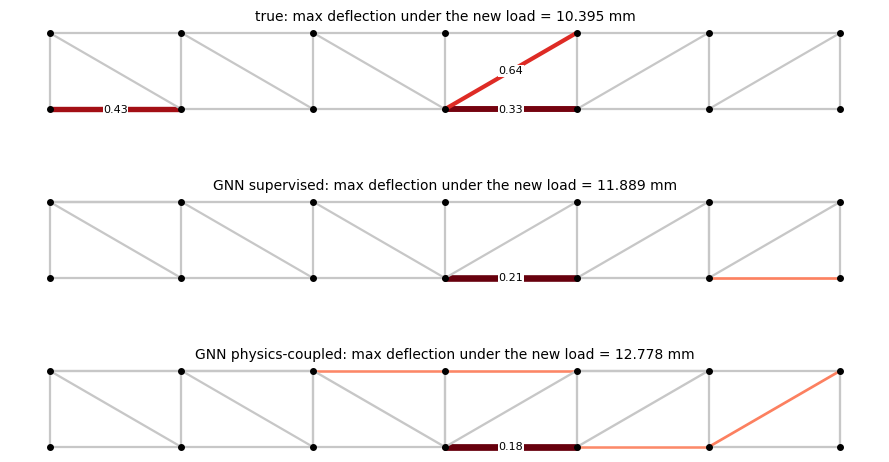

손상 부재(참): {0: 0.43, 3: 0.33, 22: 0.64}
지도학습형이 가장 낮게 본 부재: {3: 0.21, 5: 0.91, 6: 0.95}
물리결합형이 가장 낮게 본 부재: {3: 0.18, 24: 0.91, 9: 0.93}


In [8]:
off7 = sum(len(t["mem"]) for t in test_set[:7]); sl = slice(off7, off7 + len(t7["mem"]))
fig, axs = plt.subplots(3, 1, figsize=(9, 5.6))
for ax, (name, s) in zip(axs, [("true", t7["s"]), ("GNN supervised", s_sup[sl]), ("GNN physics-coupled", s_phy[sl])]):
    draw_s(ax, t7, s, f"{name}: max deflection under the new load = {max_defl(t7, t7['mem'], np.clip(s, 1e-3, None)):.3f} mm")
plt.tight_layout(); plt.show()
print("손상 부재(참):", {k: round(float(t7["s"][k]), 2) for k in t7["dmg"]})
print("지도학습형이 가장 낮게 본 부재:", {int(k): round(float(s_sup[sl][k]), 2) for k in np.argsort(s_sup[sl])[:len(t7["dmg"])]})
print("물리결합형이 가장 낮게 본 부재:", {int(k): round(float(s_phy[sl][k]), 2) for k in np.argsort(s_phy[sl])[:len(t7["dmg"])]})

## 8. 측정점이 적으면 — 해가 하나로 정해지지 않는다
변위계를 **아래현 절점의 수직 변위에만** 붙였다고 하자. 시험 트러스 7번이면 내부 절점 5개 × 하중 3 = 식 15개인데, 미지수(부재)는 25개다. 식보다 미지수가 많다.

트러스별 역해석(4절)을 **두 출발점**(모두 $s = 1$ / 모두 $s = 0.6$)에서 돌려 본다. 계측된 것만 맞추면 되므로 손실은 둘 다 0에 가까워진다. 그렇다면 강성도 같게 나올까?

In [9]:
dsm7 = BatchDSM([t7], [t7["mem"]], sensors="bottom")
print(f"계측 자유도 {int(dsm7.mask.sum())}개 × 하중 {NC} = 식 {int(dsm7.mask.sum()) * NC}개 · 미지수(부재) {len(t7['mem'])}개")
res = {}
for s0 in (1.0, 0.6):
    s_hat, l_hat = per_truss_inverse(dsm7, len(t7["mem"]), s0=s0)
    res[f"출발 s = {s0}"] = dict(계측점_손실=l_hat, 강성_MAE=np.abs(s_hat - t7["s"]).mean(),
                               새하중_처짐_mm=max_defl(t7, t7["mem"], s_hat), s=s_hat)
    print(f"출발 s = {s0}: 계측점 손실 {l_hat:.1e} · 강성 MAE {res[f'출발 s = {s0}']['강성_MAE']:.3f}"
          f" · 새 하중 최대 처짐 {res[f'출발 s = {s0}']['새하중_처짐_mm']:.3f} mm (참 {max_defl(t7, t7['mem'], t7['s']):.3f} mm)")
ds = np.abs(res["출발 s = 1.0"]["s"] - res["출발 s = 0.6"]["s"])
print(f"두 답의 강성 차: 최대 {ds.max():.3f} · 0.05 넘게 다른 부재 {int((ds > 0.05).sum())}개 / {len(ds)}")

계측 자유도 5개 × 하중 3 = 식 15개 · 미지수(부재) 25개


출발 s = 1.0: 계측점 손실 1.7e-06 · 강성 MAE 0.111 · 새 하중 최대 처짐 10.386 mm (참 10.395 mm)


출발 s = 0.6: 계측점 손실 8.7e-06 · 강성 MAE 0.164 · 새 하중 최대 처짐 10.406 mm (참 10.395 mm)
두 답의 강성 차: 최대 0.400 · 0.05 넘게 다른 부재 11개 / 25


- 두 출발점 모두 **계측은 맞히지만 강성은 다르다** → 이 계측만으로는 해가 하나로 정해지지 않는다
- 계측과 비슷한 응답(아래현 수직 처짐)은 잘 맞히더라도, 강성 자체는 모른다
- 어떤 방법이든 **계측에 없는 정보는 만들어 내지 못한다**. 해결책은 측정점을 늘리거나(센서 배치 설계), 사전 지식(예: 대부분의 부재는 멀쩡하다)을 더하는 것이다

## 9. 3단계 — 존재와 강성을 한 번에 (강성 0 = 부재 없음)
- 예제 노트북 1과 **같은 시험 문제**: 같은 시험 트러스 20동에서 **같은 부재**를 가린다. 다른 점은 실제 구조물의 **계측 변위**가 함께 주어진다는 것이다. 가린 부재도 실제 구조물에는 있으므로 변위에 영향을 준다
- 후보는 예제 노트북 1의 7절과 같다. 길이가 패널 대각선 × 1.05 이하인 절점 쌍이며, 보이는 부재 · 가린 부재 · 비부재(예: 반대 대각선)가 섞여 있다
- 모델은 후보마다 강성비 $s$ 를 낸다. 목표는 부재 → 참 강성비, 비부재 → **0**이다. 학습은 1단계처럼 에폭마다 부재 20%를 무작위로 가린다(시작값 $s = 0.5$)
- 물리결합형에서는 후보를 모두 부재로 넣고(강성 $\hat s$) 직접강성법을 푼다. $\hat s ≈ 0$ 인 후보가 있어도 강성행렬이 특이해지지 않게 바닥값 0.001을 더한다
- 채점은 예제 노트북 1과 같은 정의이고, 강성과 구조해석 지표를 더한다
  - 대각재 방향 승률
  - **완전 복원**: Maxwell 식으로 정한 빠진 개수 $k$ 만큼 상위 $k$ 후보를 고른다
  - 가까운 후보 AUC: 가린 부재 vs 비부재 후보
  - 부재 강성 MAE
  - 복원 트러스(보이는 부재 + 고른 $k$ 개, 예측 강성)의 새 하중 처짐 오차. 필요한 부재를 $s ≈ 0$ 으로 보면 처짐이 발산하므로, 10(= 1000%)에서 자르고 **중앙값**과 **10% 이내 비율**로 본다

In [10]:
def near_pairs(tr):                                                 # 예제 노트북 1의 7절 후보: 길이 ≤ 1.05 × 패널 대각선
    L = 1.05 * math.hypot(tr["w"], tr["h"]); N = len(tr["pos"])
    return [canon(tr["pos"], u, v) for u in range(N) for v in range(u + 1, N) if np.hypot(*(tr["pos"][u] - tr["pos"][v])) <= L]

def hidden_members(tset, hid_order, frac=0.2):                       # 예제 노트북 1의 hide()와 같은 '가린 부재'(트러스마다 부재 번호)
    k = int(frac * len(hid_order)); hid = set(hid_order[:k].tolist()); out, off = [], 0
    for t in tset:
        out.append(sorted(j for j in range(len(t["mem"])) if off + j in hid)); off += len(t["mem"])
    return out

def evaluate_stage3(tset, near_list, hid_list, s_pred):
    off, ys, ss, wins, full, n_k, mae, derr = 0, [], [], [], 0, 0, [], []
    for t, P, hid in zip(tset, near_list, hid_list):
        s = s_pred[off:off + len(P)]; off += len(P); idx = {p: i for i, p in enumerate(P)}
        memc = [canon(t["pos"], u, v) for u, v in t["mem"]]; hidc = {memc[j] for j in hid}; vis = set(memc) - hidc
        cand = [i for i, p in enumerate(P) if p not in vis]
        ys += [P[i] in hidc for i in cand]; ss += [s[i] for i in cand]
        for dg, ot in zip(t["diag"], t["other"]):                    # 가린 대각재마다: 진짜 대각선 vs 반대 대각선
            a, b = idx[canon(t["pos"], *dg)], idx[canon(t["pos"], *ot)]
            if P[a] in hidc: wins.append(float(s[a] > s[b]) + 0.5 * float(s[a] == s[b]))
        mae += [abs(s[idx[p]] - t["s"][j]) for j, p in enumerate(memc)]
        k = len(hid)
        if k == 0: continue                                          # 가린 부재가 없는 트러스는 복원 채점에서 빼기(1단계와 같게)
        top = [cand[i] for i in np.argsort(-np.array([s[i] for i in cand]), kind="stable")[:k]]
        full += {P[i] for i in top} == hidc; n_k += 1
        rest = sorted(vis) + [P[i] for i in top]
        try:
            d0, d1 = max_defl(t, t["mem"], t["s"]), max_defl(t, rest, np.clip([s[idx[p]] for p in rest], 1e-3, None))
            derr.append(min(abs(d1 - d0) / d0, 10.0))                 # 10 = 1000% 이상(사실상 불안정)으로 자른다
        except np.linalg.LinAlgError:
            derr.append(10.0)
    derr = np.array(derr)
    return {"가까운 후보 AUC": roc_auc_score(ys, ss), "대각재 방향 승률": np.mean(wins), "완전 복원 비율": full / n_k,
            "부재 강성 MAE": np.mean(mae), "처짐 오차 중앙값": np.median(derr), "처짐 10% 이내 비율": np.mean(derr <= 0.10)}

near_tr, near_te = [near_pairs(t) for t in train_set], [near_pairs(t) for t in test_set]
hid_te = hidden_members(test_set, hid_order)
print(f"가린 부재 {sum(map(len, hid_te))}개 · 시험 트러스 7번에서 가린 부재: "
      f"{sorted(tuple(sorted(test_set[7]['mem'][j])) for j in hid_te[7])}")
tb3_tr, tb3_te = TrussBatch(train_set, near_tr, u_scale), TrussBatch(test_set, near_te, u_scale)
dsm3_tr = BatchDSM(train_set, near_tr)
vis_te = torch.ones(tb3_te.n_mem, dtype=torch.bool); off = 0
for t, hid in zip(test_set, hid_te):
    for j in hid: vis_te[off + j] = False
    off += len(t["mem"])
print(f"후보 쌍: 학습 {len(tb3_tr.pu)} · 시험 {len(tb3_te.pu)} (비부재 후보 {int((tb3_te.mp < 0).sum())})")

rows3 = {"고전: 평형식 최소제곱(s ≥ 0)": evaluate_stage3(test_set, near_te, hid_te,
                                                   np.concatenate([equilibrium_ls(t, P, nonneg=True) for t, P in zip(test_set, near_te)]))}
s3 = {}
for mode in ("지도학습형", "물리결합형", "혼합"):
    t = time.time(); mdl = train_gnn(tb3_tr, dsm3_tr, mode, hide=0.2, s_init=0.5)
    s3[mode] = predict(mdl, tb3_te, vis_te)
    rows3[f"GNN {mode}"] = evaluate_stage3(test_set, near_te, hid_te, s3[mode]); print(f"{mode} 300에폭 ⏱ {time.time() - t:.1f}초")
pd.DataFrame(rows3).T.round(3)

가린 부재 95개 · 시험 트러스 7번에서 가린 부재: [(0, 7), (2, 9), (3, 4), (3, 10), (5, 6), (7, 8), (8, 9)]
후보 쌍: 학습 1402 · 시험 624 (비부재 후보 148)


지도학습형 300에폭 ⏱ 0.6초


물리결합형 300에폭 ⏱ 1.0초


혼합 300에폭 ⏱ 1.0초


,가까운 후보 AUC,대각재 방향 승률,완전 복원 비율,부재 강성 MAE,처짐 오차 중앙값,처짐 10% 이내 비율
고전: 평형식 최소제곱(s ≥ 0),1.000,1.00,1.00,0.000,0.000,1.0
GNN 지도학습형,0.959,1.00,0.60,0.072,0.165,0.5
GNN 물리결합형,0.844,0.95,0.35,0.235,10.000,0.0
GNN 혼합,0.963,0.95,0.65,0.087,0.072,0.6


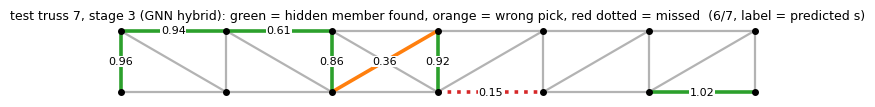

놓친 부재 (3, 4): 예측 s 0.15 · 참 s 0.33
잘못 고른 쌍 (2, 10): 예측 s 0.36 · 실제로는 부재가 아님


In [11]:
P7, hid7 = near_te[7], hid_te[7]; o7 = sum(len(P) for P in near_te[:7]); s7 = s3["혼합"][o7:o7 + len(P7)]
memc7 = [canon(t7["pos"], u, v) for u, v in t7["mem"]]; hidc7 = {memc7[j] for j in hid7}; vis7 = set(memc7) - hidc7
cand7 = [i for i, p in enumerate(P7) if p not in vis7]
top7 = {P7[i] for i in [cand7[i] for i in np.argsort(-np.array([s7[i] for i in cand7]), kind="stable")[:len(hid7)]]}
fig, ax = plt.subplots(figsize=(9, 3.2))
for u, v in vis7: ax.plot(*zip(t7["pos"][u], t7["pos"][v]), color="0.7", lw=1.6)
for u, v in top7 | hidc7:
    ok, chosen = (u, v) in hidc7, (u, v) in top7
    col = "tab:green" if ok and chosen else ("tab:orange" if chosen else "tab:red")
    ax.plot(*zip(t7["pos"][u], t7["pos"][v]), color=col, lw=2.6, ls="-" if chosen else ":")
    ax.text(*(t7["pos"][u] + t7["pos"][v]) / 2, f"{s7[P7.index((u, v))]:.2f}", fontsize=8, ha="center", va="center",
            bbox=dict(fc="white", ec="none", pad=0.4))
ax.scatter(*t7["pos"].T, s=16, color="k", zorder=3); ax.set_aspect("equal"); ax.axis("off")
ax.set_title(f"test truss 7, stage 3 (GNN hybrid): green = hidden member found, orange = wrong pick, red dotted = missed"
             f"  ({len(top7 & hidc7)}/{len(hid7)}, label = predicted s)", fontsize=9)
plt.show()
sm7 = {p: float(t7["s"][j]) for j, p in enumerate(memc7)}
for p in sorted(hidc7 - top7): print(f"놓친 부재 {p}: 예측 s {s7[P7.index(p)]:.2f} · 참 s {sm7[p]:.2f}")
for p in sorted(top7 - hidc7): print(f"잘못 고른 쌍 {p}: 예측 s {s7[P7.index(p)]:.2f} · 실제로는 부재가 아님")

## 10. 시드 3개로 다시 · 한 표로 비교
트러스 생성 · 손상 · 하중 · 학습을 시드 0, 1, 2로 반복해 평균 ± 표준편차를 본다. 스레드를 1개로 묶어 두었으므로(0절) 같은 컴퓨터에서 다시 실행하면 같은 숫자가 나온다. 컴퓨터(운영체제 · CPU)가 바뀌면 부동소수점 차이로 조금 달라질 수 있다. 시드마다 트러스와 가린 부재는 예제 노트북 1의 10절과 같다. 5절 피처에서 **평형 잔차를 뺀** 행을 더해, *물리를 피처로 넣기*(잔차)와 *손실로 넣기*(물리결합형)를 따로 본다.

In [12]:
t = time.time(); runs2, runs3 = [], []
for seed in (0, 1, 2):
    trs, tes, hord = make_data(seed)
    us = np.concatenate([x["U"][free_dofs(len(x["pos"]), x["n"])].ravel() for x in trs]).std()
    A, B = TrussBatch(trs, mem_c(trs), us), TrussBatch(tes, mem_c(tes), us); Dtr = BatchDSM(trs, mem_c(trs))
    runs2.append(dict(seed=seed, 방법="기준선: s = 1", **evaluate_s(tes, np.ones(B.n_mem))))
    runs2.append(dict(seed=seed, 방법="고전: 평형식 최소제곱", **evaluate_s(tes, np.concatenate([equilibrium_ls(x) for x in tes]))))
    runs2.append(dict(seed=seed, 방법="고전: 트러스별 역해석", **evaluate_s(tes, per_truss_inverse(BatchDSM(tes, [x["mem"] for x in tes]), B.n_mem)[0])))
    for mode, resid in (("지도학습형", False), ("물리결합형", False), ("지도학습형", True), ("물리결합형", True), ("혼합", True)):
        mdl = train_gnn(A, Dtr, mode, seed=seed, resid=resid)
        runs2.append(dict(seed=seed, 방법=f"GNN {mode}" + ("" if resid else " (잔차 피처 없음)"),
                          **evaluate_s(tes, predict(mdl, B, all_vis(B), resid))))
    ntr, nte, hte = [near_pairs(x) for x in trs], [near_pairs(x) for x in tes], hidden_members(tes, hord)
    A3, B3, D3 = TrussBatch(trs, ntr, us), TrussBatch(tes, nte, us), BatchDSM(trs, ntr)
    v3 = torch.ones(B3.n_mem, dtype=torch.bool); o = 0
    for x, hid in zip(tes, hte):
        for j in hid: v3[o + j] = False
        o += len(x["mem"])
    runs3.append(dict(seed=seed, 방법="고전: 평형식 최소제곱(s ≥ 0)",
                      **evaluate_stage3(tes, nte, hte, np.concatenate([equilibrium_ls(x, P, nonneg=True) for x, P in zip(tes, nte)]))))
    for mode in ("지도학습형", "물리결합형", "혼합"):
        mdl = train_gnn(A3, D3, mode, seed=seed, hide=0.2, s_init=0.5)
        runs3.append(dict(seed=seed, 방법=f"GNN {mode}", **evaluate_stage3(tes, nte, hte, predict(mdl, B3, v3))))
print(f"⏱ {time.time() - t:.1f}초")
cols2 = ["강성 MAE", "손상 AUC", "손상 적중", "변위 오차(계측 하중)", "처짐 오차(새 하중)"]
table2 = pd.DataFrame(runs2).groupby("방법", sort=False)[cols2].agg(["mean", "std"]).round(3)
table2

⏱ 24.6초


강성 MAE        손상 AUC         손상 적중        변위 오차(계측 하중)  \
                       mean    std   mean    std   mean    std         mean   
방법                                                                            
기준선: s = 1            0.040  0.001  0.500  0.000  0.094  0.046        0.102   
고전: 평형식 최소제곱          0.000  0.000  1.000  0.000  1.000  0.000        0.000   
고전: 트러스별 역해석          0.003  0.001  1.000  0.000  1.000  0.000        0.000   
GNN 지도학습형 (잔차 피처 없음)  0.053  0.004  0.753  0.028  0.419  0.043        1.910   
GNN 물리결합형 (잔차 피처 없음)  0.053  0.012  0.720  0.034  0.450  0.050        0.119   
GNN 지도학습형             0.045  0.002  0.822  0.039  0.550  0.094        0.266   
GNN 물리결합형             0.057  0.010  0.778  0.056  0.519  0.172        0.093   
GNN 혼합                0.044  0.003  0.857  0.030  0.542  0.121        0.157   

                            처짐 오차(새 하중)         
                        std        mean    std  
방법                                              
기준선: s = 1            0.019       0.083  0.016  
고전: 평형식 최소제곱          0.000       0.000  0.000  
고전: 트러스별 역해석          0.000       0.000  0.000  
GNN 지도학습형 (잔차 피처 없음)  1.632       2.154  1.847  
GNN 물리결합형 (잔차 피처 없음)  0.030       0.101  0.029  
GNN 지도학습형             0.140       0.262  0.159  
GNN 물리결합형             0.025       0.075  0.028  
GNN 혼합                0.056       0.142  0.060

In [13]:
cols3 = ["대각재 방향 승률", "완전 복원 비율", "가까운 후보 AUC", "부재 강성 MAE", "처짐 오차 중앙값", "처짐 10% 이내 비율"]
table3 = pd.DataFrame(runs3).groupby("방법", sort=False)[cols3].agg(["mean", "std"]).round(3)
table3

대각재 방향 승률        완전 복원 비율        가까운 후보 AUC         \
                         mean    std     mean    std       mean    std   
방법                                                                       
고전: 평형식 최소제곱(s ≥ 0)     1.000  0.000    1.000  0.000      1.000  0.000   
GNN 지도학습형               0.946  0.047    0.633  0.153      0.958  0.021   
GNN 물리결합형               0.834  0.102    0.200  0.150      0.794  0.092   
GNN 혼합                  0.902  0.042    0.583  0.076      0.960  0.016   

                    부재 강성 MAE        처짐 오차 중앙값        처짐 10% 이내 비율         
                         mean    std      mean    std         mean    std  
방법                                                                         
고전: 평형식 최소제곱(s ≥ 0)     0.000  0.000     0.000  0.000        1.000  0.000  
GNN 지도학습형               0.079  0.013     0.320  0.335        0.400  0.173  
GNN 물리결합형               0.217  0.024    10.000  0.000        0.067  0.076  
GNN 혼합                  0.084  0.004     0.126  0.066        0.467  0.126

In [14]:
print(f"⏱ 노트북 전체 {time.time() - T0:.0f}초")

⏱ 노트북 전체 32초


## 11. 정리
- **링크 가중치 예측 = 엣지 회귀.** 인코더(2층 GCN)는 그대로 두고 두 가지만 바꿨다(5절). 디코더는 엣지 회귀 헤드로, 손실은 BCE에서 MSE로. 강성 0을 '부재 없음'으로 두면 존재 예측과 하나가 된다(9절)
- **먼저 물리로 풀어 본다**
  - 모든 절점 변위를 재면 평형식이 강성에 대해 선형이라, 최소제곱으로 정확히 풀린다(4절)
  - 힘을 받지 않는 부재의 강성은 어떤 방법으로도 알 수 없다. 흔한 재하 시험 3종에서는 부재의 9.6%가 그랬다(3절)
  - 측정점이 적으면 계측을 똑같이 맞히는 강성이 여럿이다(8절)
- **지도학습형 vs 물리결합형** (10절, 시드 3개)
  - 손상 위치를 찾는 능력(손상 AUC)은 지도학습형 0.822 · 혼합 0.857이 물리결합형 0.778보다 높다
  - 예측 강성으로 새 하중을 해석하면 이야기가 달라진다. 지도학습형의 처짐 오차 0.262는 '손상 없음 가정'의 0.083보다 크다. 학습 트러스에서 배운 강성 값이, 처음 보는 트러스에서는 응답을 틀리게 만든 것이다
  - 물리결합형(0.075)만 기준선 수준을 지켰고, 혼합(0.142)은 그 사이였다 → **지표가 좋아도 구조해석으로 검증해야 한다**(예제 노트북 1과 같은 교훈)
  - 물리결합형은 강성 라벨 없이 하중과 계측 변위만으로 배운다. 정답 강성을 모르는 실제 구조물의 계측으로도 학습할 수 있다는 뜻이다
- **물리를 피처로 넣기**: $s = 1$ 가정 평형 잔차를 피처로 넣었다
  - 손상 AUC가 올랐다: 지도학습형 0.753 → 0.822, 물리결합형 0.720 → 0.778
  - 지도학습형의 처짐 오차가 2.154 → 0.262로 줄었다
- **3단계(존재 + 강성)**: 거동 정보가 1단계의 대칭을 깼다
  - 대각재 방향 승률: 지도학습형 0.946 vs 1단계 최고 0.805
  - 완전 복원: 지도학습형 0.633 vs 1단계 최고 0.467
  - 물리결합형 단독은 '없는 부재'를 가려내지 못했다(완전 복원 0.200)
  - 복원 트러스의 처짐은 혼합이 가장 잘 맞혔다(중앙값 0.126)
- **손상된 부재는 '없는 부재'와 헷갈린다.** 강성이 낮기 때문이다(9절 시험 트러스 7의 놓친 부재를 보라). 강성 0 = 부재 없음으로 합치면 생기는 모호함이다
- 이 노트북의 숫자는 각 셀의 출력이다. 같은 컴퓨터에서는 다시 실행해도 같고, 컴퓨터가 바뀌면 조금 달라질 수 있다

## ✏️ 직접 해 보기 (정답은 없습니다)
1. 6절 혼합 손실에서 물리결합형 손실에 곱하는 가중치를 0.1 · 10으로 바꿔 보라. 손상 AUC와 처짐 오차는 어떻게 움직이는가?
2. 계측 변위에 잡음(예: 변위의 1%)을 넣으면 4절 평형식 최소제곱은 여전히 정확한가? 트러스별 역해석 · GNN과 비교하라
3. 8절에서 위현 절점의 수직 변위를 계측에 더하면 두 출발점의 답이 가까워지는가? 몇 개를 더해야 하나로 정해지는가?
4. 2절 하중을 3절의 흔한 재하 시험 3종으로 바꿔 데이터를 만들면(무응력 부재가 생긴다) 5–6절의 결과는 어떻게 되는가?